<h1>Question 5</h1>

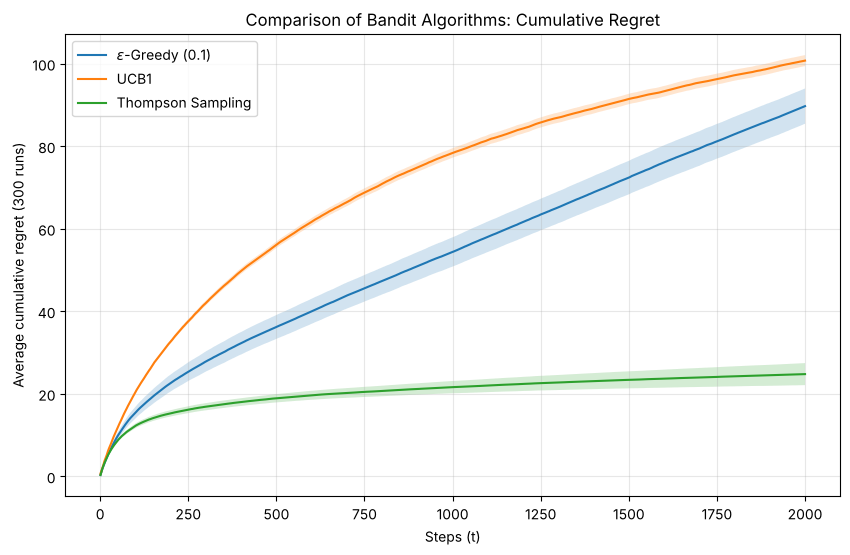

$\epsilon$-Greedy (0.1)    regret at T=2000:   89.7 ±  4.3
UCB1                       regret at T=2000:  100.8 ±  1.3
Thompson Sampling          regret at T=2000:   24.8 ±  2.7


In [1]:
import numpy as np
import matplotlib.pyplot as plt

TRUE_PROBS = np.array([0.1, 0.3, 0.7, 0.2, 0.5])   # arm 3 (0.7) is the best
T = 2000
RUNS = 300
EPSILON = 0.1


def run_once(algorithm, rewards, rng):
    """One run of one algorithm. rewards[t, i] is the reward arm i would give at step t,
    so every algorithm faces exactly the same random outcomes (common random numbers)."""
    k = len(TRUE_PROBS)
    counts = np.zeros(k)
    values = np.zeros(k)
    alphas = np.ones(k)
    betas = np.ones(k)
    regret = np.zeros(T)
    total = 0.0
    best = TRUE_PROBS.max()
    for t in range(T):
        if algorithm == "epsilon_greedy":
            if rng.random() < EPSILON:
                arm = rng.integers(k)
            else:
                arm = rng.choice(np.flatnonzero(values == values.max()))
        elif algorithm == "ucb":
            if t < k:
                arm = t
            else:
                arm = int(np.argmax(values + np.sqrt(2 * np.log(t + 1) / counts)))
        else:  # Thompson sampling with a Beta(1, 1) prior
            arm = int(np.argmax(rng.beta(alphas, betas)))
        r = rewards[t, arm]
        counts[arm] += 1
        values[arm] += (r - values[arm]) / counts[arm]
        alphas[arm] += r
        betas[arm] += 1 - r
        total += best - TRUE_PROBS[arm]
        regret[t] = total
    return regret


def main():
    rng = np.random.default_rng(42)
    names = {"epsilon_greedy": r"$\epsilon$-Greedy (0.1)", "ucb": "UCB1", "thompson": "Thompson Sampling"}
    curves = {a: np.zeros((RUNS, T)) for a in names}
    for run in range(RUNS):
        rewards = (rng.random((T, len(TRUE_PROBS))) < TRUE_PROBS).astype(float)
        for a in names:
            curves[a][run] = run_once(a, rewards, rng)

    t = np.arange(1, T + 1)
    plt.figure(figsize=(10, 6))
    for a, label in names.items():
        mean = curves[a].mean(axis=0)
        sem = curves[a].std(axis=0, ddof=1) / np.sqrt(RUNS)
        plt.plot(t, mean, label=label)
        plt.fill_between(t, mean - 1.96 * sem, mean + 1.96 * sem, alpha=0.2)
    plt.xlabel("Steps (t)")
    plt.ylabel(f"Average cumulative regret ({RUNS} runs)")
    plt.title("Comparison of Bandit Algorithms: Cumulative Regret")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.savefig("Q5-bandit_algorithms_comparison.png", dpi=200, bbox_inches="tight")
    plt.show()

    for a, label in names.items():
        final = curves[a][:, -1]
        print(f"{label:<26} regret at T={T}: {final.mean():6.1f} ± {1.96 * final.std(ddof=1) / np.sqrt(RUNS):4.1f}")


main()


<h1>Question 6</h1>

T = 500
  share of pulls (TS)          : [0.008 0.034 0.936 0.022]
  average of pi_i(t) over steps: [0.004 0.034 0.938 0.024]
  max |difference|             : 0.004
  pi_i at the end of the run   : [0.    0.011 0.98  0.009]


T = 1000
  share of pulls (TS)          : [0.004 0.013 0.973 0.01 ]
  average of pi_i(t) over steps: [0.008 0.014 0.969 0.009]
  max |difference|             : 0.004
  pi_i at the end of the run   : [0.001 0.002 0.997 0.   ]


T = 5000
  share of pulls (TS)          : [0.004 0.006 0.984 0.006]
  average of pi_i(t) over steps: [0.004 0.006 0.984 0.006]
  max |difference|             : 0.001
  pi_i at the end of the run   : [0. 0. 1. 0.]


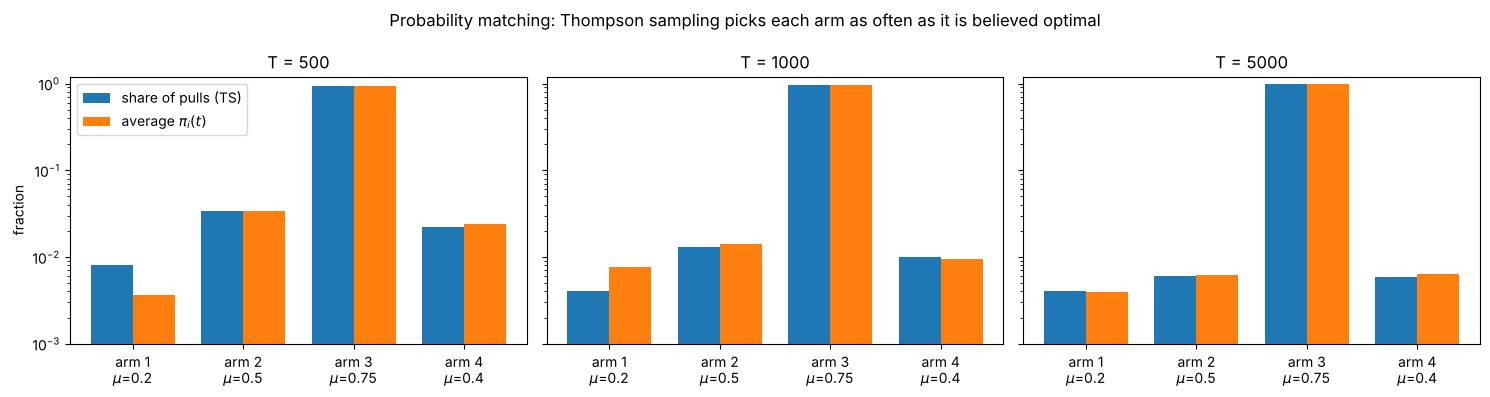

In [2]:
import numpy as np
import matplotlib.pyplot as plt

TRUE_PROBS = np.array([0.2, 0.5, 0.75, 0.4])
T_VALUES = [500, 1000, 5000]
MC_SAMPLES = 4000


def prob_optimal(alphas, betas, rng, n=MC_SAMPLES):
    """Monte Carlo estimate of pi_i = P(theta_i is the largest | history)."""
    samples = rng.beta(alphas, betas, size=(n, len(alphas)))
    return np.bincount(samples.argmax(axis=1), minlength=len(alphas)) / n


def run(T, rng):
    """Thompson sampling that also records pi(t), the posterior probability that each
    arm is optimal just before step t. Probability matching says
    P(A_t = i | history) = pi_i(t), so over a run the share of pulls of arm i must
    agree with the average of pi_i(t) over the same steps."""
    k = len(TRUE_PROBS)
    alphas = np.ones(k); betas = np.ones(k)
    pi_sum = np.zeros(k); counts = np.zeros(k)
    for _ in range(T):
        pi_sum += prob_optimal(alphas, betas, rng, n=1000)
        arm = int(np.argmax(rng.beta(alphas, betas)))
        r = float(rng.random() < TRUE_PROBS[arm])
        alphas[arm] += r; betas[arm] += 1 - r
        counts[arm] += 1
    return counts / T, pi_sum / T, prob_optimal(alphas, betas, rng)


def main():
    rng = np.random.default_rng(42)
    rows = []
    for T in T_VALUES:
        freq, avg_pi, final_pi = run(T, rng)
        rows.append((T, freq, avg_pi, final_pi))
        print(f"T = {T}")
        print(f"  share of pulls (TS)          : {np.round(freq, 3)}")
        print(f"  average of pi_i(t) over steps: {np.round(avg_pi, 3)}")
        print(f"  max |difference|             : {np.abs(freq - avg_pi).max():.3f}")
        print(f"  pi_i at the end of the run   : {np.round(final_pi, 3)}")

    fig, axes = plt.subplots(1, len(T_VALUES), figsize=(15, 4), sharey=True)
    x = np.arange(len(TRUE_PROBS)); w = 0.38
    for ax, (T, freq, avg_pi, _) in zip(axes, rows):
        ax.bar(x - w / 2, freq, w, label="share of pulls (TS)")
        ax.bar(x + w / 2, avg_pi, w, label=r"average $\pi_i(t)$")
        ax.set_yscale("log"); ax.set_ylim(1e-3, 1.2)
        ax.set_xticks(x); ax.set_xticklabels([f"arm {i + 1}\n$\\mu$={p}" for i, p in enumerate(TRUE_PROBS)])
        ax.set_title(f"T = {T}")
    axes[0].set_ylabel("fraction"); axes[0].legend()
    plt.suptitle("Probability matching: Thompson sampling picks each arm as often as it is believed optimal")
    plt.tight_layout()
    plt.savefig("Q6.png", dpi=200, bbox_inches="tight")
    plt.show()


main()


<h1>Question 7</h1>

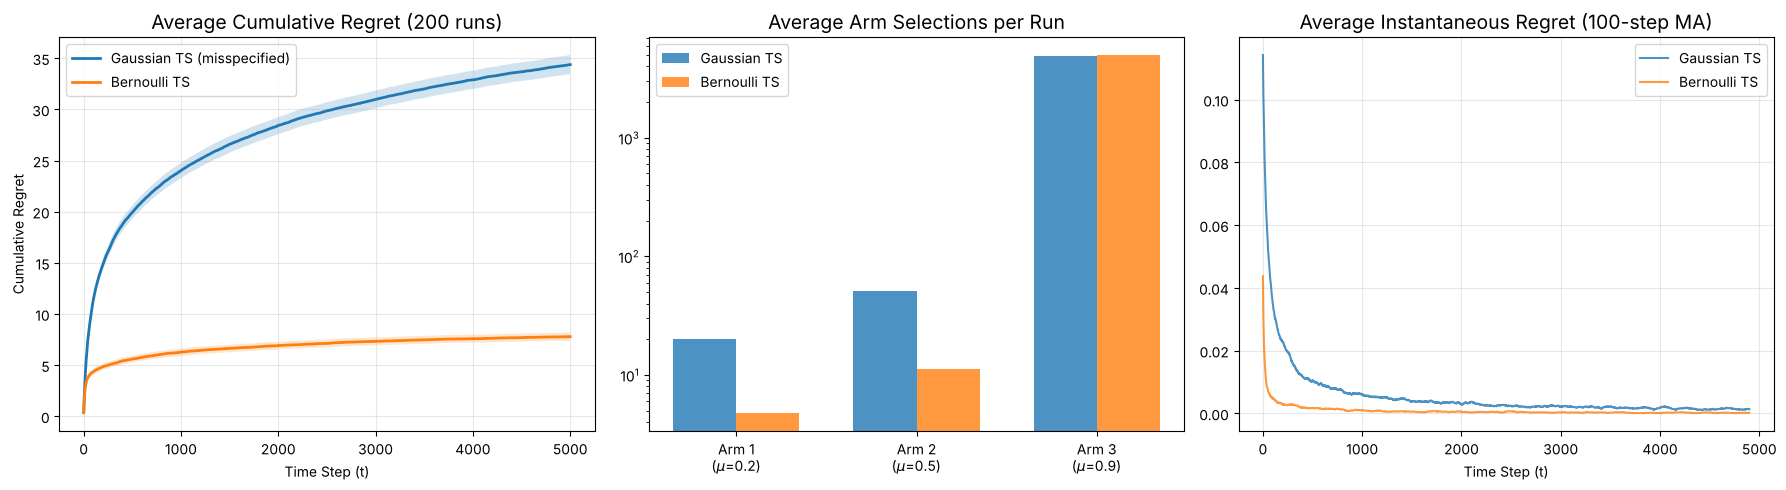

Algorithm                    | Regret at T    | Best-arm share
--------------------------------------------------------------
Gaussian TS (misspecified)   |   34.4 ±  0.9 |  98.6%
Bernoulli TS                 |    7.8 ±  0.4 |  99.7%


In [3]:
import numpy as np
import matplotlib.pyplot as plt

TRUE_MEANS = np.array([0.2, 0.5, 0.9])   # Bernoulli arms: rewards are 0 or 1
K = len(TRUE_MEANS)
T = 5000
RUNS = 200
PRIOR_VAR = 10.0            # Gaussian prior N(0, 10) on each mean
ASSUMED_NOISE_VAR = 1.0     # variance the Gaussian model assumes for each reward


def gaussian_ts(rewards, rng):
    """Thompson sampling with a Normal likelihood (known variance) and Normal prior,
    applied to the same binary rewards as the Bernoulli version: a misspecified model."""
    mean = np.zeros(K)
    var = np.full(K, PRIOR_VAR)
    counts = np.zeros(K)
    regret = np.zeros(T)
    total = 0.0
    for t in range(T):
        arm = int(np.argmax(rng.normal(mean, np.sqrt(var))))
        r = rewards[t, arm]
        post_var = 1.0 / (1.0 / var[arm] + 1.0 / ASSUMED_NOISE_VAR)
        mean[arm] = post_var * (mean[arm] / var[arm] + r / ASSUMED_NOISE_VAR)
        var[arm] = post_var
        counts[arm] += 1
        total += TRUE_MEANS.max() - TRUE_MEANS[arm]
        regret[t] = total
    return regret, counts


def bernoulli_ts(rewards, rng):
    """Thompson sampling with the Beta-Bernoulli model (correctly specified)."""
    alphas = np.ones(K)
    betas = np.ones(K)
    counts = np.zeros(K)
    regret = np.zeros(T)
    total = 0.0
    for t in range(T):
        arm = int(np.argmax(rng.beta(alphas, betas)))
        r = rewards[t, arm]
        alphas[arm] += r
        betas[arm] += 1 - r
        counts[arm] += 1
        total += TRUE_MEANS.max() - TRUE_MEANS[arm]
        regret[t] = total
    return regret, counts


def main():
    rng = np.random.default_rng(42)
    reg_g = np.zeros((RUNS, T)); reg_b = np.zeros((RUNS, T))
    cnt_g = np.zeros((RUNS, K)); cnt_b = np.zeros((RUNS, K))
    for run in range(RUNS):
        # Both algorithms see exactly the same binary reward table in this run.
        rewards = (rng.random((T, K)) < TRUE_MEANS).astype(float)
        reg_g[run], cnt_g[run] = gaussian_ts(rewards, rng)
        reg_b[run], cnt_b[run] = bernoulli_ts(rewards, rng)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    t = np.arange(1, T + 1)
    for reg, label in [(reg_g, "Gaussian TS (misspecified)"), (reg_b, "Bernoulli TS")]:
        m = reg.mean(axis=0); e = 1.96 * reg.std(axis=0, ddof=1) / np.sqrt(RUNS)
        axes[0].plot(t, m, label=label, linewidth=2)
        axes[0].fill_between(t, m - e, m + e, alpha=0.2)
    axes[0].set_title(f"Average Cumulative Regret ({RUNS} runs)", fontsize=14)
    axes[0].set_xlabel("Time Step (t)"); axes[0].set_ylabel("Cumulative Regret")
    axes[0].legend(); axes[0].grid(True, alpha=0.3)

    x = np.arange(K); width = 0.35
    axes[1].bar(x - width / 2, cnt_g.mean(axis=0), width, label="Gaussian TS", alpha=0.8)
    axes[1].bar(x + width / 2, cnt_b.mean(axis=0), width, label="Bernoulli TS", alpha=0.8)
    axes[1].set_title("Average Arm Selections per Run", fontsize=14)
    axes[1].set_xticks(x)
    axes[1].set_xticklabels([f"Arm {i + 1}\n($\\mu$={TRUE_MEANS[i]})" for i in range(K)])
    axes[1].set_yscale("log"); axes[1].legend()

    window = 100
    for reg, label in [(reg_g, "Gaussian TS"), (reg_b, "Bernoulli TS")]:
        inst = np.diff(np.insert(reg.mean(axis=0), 0, 0))
        axes[2].plot(np.convolve(inst, np.ones(window) / window, mode="valid"), label=label, alpha=0.8)
    axes[2].set_title(f"Average Instantaneous Regret ({window}-step MA)", fontsize=14)
    axes[2].set_xlabel("Time Step (t)"); axes[2].legend(); axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig("Q7-gaussian_vs_bernoulli.png", dpi=200, bbox_inches="tight")
    plt.show()

    print(f"{'Algorithm':<28} | {'Regret at T':<14} | Best-arm share")
    print("-" * 62)
    for reg, cnt, label in [(reg_g, cnt_g, "Gaussian TS (misspecified)"), (reg_b, cnt_b, "Bernoulli TS")]:
        f = reg[:, -1]
        print(f"{label:<28} | {f.mean():6.1f} ± {1.96 * f.std(ddof=1) / np.sqrt(RUNS):4.1f} | {cnt[:, 2].mean() / T * 100:5.1f}%")


main()
